<a href="https://colab.research.google.com/github/anshika-commits2007/Pneumonia-Screening-Portal-Using-Deep-Learning/blob/main/Pneumonia_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/Pediatric Chest X-ray Pneumonia")

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}"
    )

print("Dataset found at:", DATA_DIR)

Dataset found at: /content/drive/MyDrive/Pediatric Chest X-ray Pneumonia


In [ ]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

for split in ["train","test"]:
    print(f"\n{split.upper()}")

    for category in ["NORMAL", "PNEUMONIA"]:
        folder = DATA_DIR / split / category

        if folder.exists():
            count = sum(
                1 for p in folder.iterdir()
                if p.is_file()
                and p.suffix.lower() in IMAGE_EXTENSIONS
            )
            print(f"{category}: {count} images")
        else:
            print(f"{category}: folder not found")


TRAIN
NORMAL: 1349 images
PNEUMONIA: 3883 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.15,
    subset="training",
    seed=SEED,
    class_names=["NORMAL", "PNEUMONIA"]
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    shuffle=False,
    class_names=["NORMAL", "PNEUMONIA"]
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
    class_names=["NORMAL", "PNEUMONIA"]
)

print("Classes:", train_ds.class_names)


Found 5232 files belonging to 2 classes.
Using 4448 files for training.
Found 5232 files belonging to 2 classes.
Using 784 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:

from pathlib import Path
import tensorflow as tf

# Check that DATA_DIR points to your extracted dataset folder
DATA_DIR = Path(DATA_DIR)
print("Dataset location:", DATA_DIR)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.15,
    subset="training",
    seed=SEED,
    class_names=["NORMAL", "PNEUMONIA"]
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    validation_split=0.15,
    subset="validation",
    seed=SEED,
    shuffle=False,
    class_names=["NORMAL", "PNEUMONIA"]
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False,
    class_names=["NORMAL", "PNEUMONIA"]
)

print("Classes:", train_ds.class_names)

Dataset location: /content/drive/MyDrive/Pediatric Chest X-ray Pneumonia
Found 5232 files belonging to 2 classes.
Using 4448 files for training.
Found 5232 files belonging to 2 classes.
Using 784 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

print("Datasets are ready!")

Datasets are ready!


In [ ]:

from tensorflow.keras import layers, models

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Initially keep pretrained layers frozen
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# MobileNetV2 expects pixel values scaled to [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# One output: predicted score for the PNEUMONIA class
outputs = layers.Dense(1, activation="sigmoid")(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.AUC(name="auc")]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stopping]
)

Epoch 1/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 722s 5s/step - accuracy: 0.8559 - auc: 0.9075 - loss: 0.3323 - val_accuracy: 0.9643 - val_auc: 0.0000e+00 - val_loss: 0.1066
Epoch 2/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 271s 2s/step - accuracy: 0.9467 - auc: 0.9848 - loss: 0.1536 - val_accuracy: 0.9668 - val_auc: 0.0000e+00 - val_loss: 0.0873
Epoch 3/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - accuracy: 0.9530 - auc: 0.9879 - loss: 0.1295 - val_accuracy: 0.9707 - val_auc: 0.0000e+00 - val_loss: 0.0803
Epoch 4/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 266s 2s/step - accuracy: 0.9640 - auc: 0.9917 - loss: 0.1087 - val_accuracy: 0.9745 - val_auc: 0.0000e+00 - val_loss: 0.0751
Epoch 5/5
139/139 ━━━━━━━━━━━━━━━━━━━━ 318s 2s/step - accuracy: 0.9640 - auc: 0.9928 - loss: 0.0997 - val_accuracy: 0.9745 - val_auc: 0.0000e+00 - val_loss: 0.0724


In [ ]:

test_results = model.evaluate(test_ds, return_dict=True)

print("\nTest results:")
for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 98s 5s/step - accuracy: 0.8285 - auc: 0.9621 - loss: 0.4073

Test results:
accuracy: 0.8285
auc: 0.9621
loss: 0.4073


In [ ]:

model.save("/content/pneumonia_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

model.save(
    "/content/drive/MyDrive/pneumonia_model.keras"
)

print("Model saved to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved to Google Drive!


In [ ]:

import numpy as np

# Get the true labels from the test dataset
y_true = np.concatenate([
    labels.numpy().ravel() for images, labels in test_ds
]).astype(int)

# Get the model's predicted scores
y_scores = model.predict(test_ds, verbose=1).ravel()

# Convert scores into predicted classes using a 0.5 threshold
y_pred = (y_scores >= 0.5).astype(int)

print("Number of test images:", len(y_true))
print("Predictions completed!")
print("First 10 true labels:", y_true[:10])
print("First 10 predicted labels:", y_pred[:10])

20/20 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step
Number of test images: 624
Predictions completed!
First 10 true labels: [0 0 0 0 0 0 0 0 0 0]
First 10 predicted labels: [0 0 0 1 0 0 0 0 1 0]


In [ ]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn) if (tp + fn) else 0
specificity = tn / (tn + fp) if (tn + fp) else 0
precision = tp / (tp + fp) if (tp + fp) else 0
f1 = (
    2 * precision * sensitivity / (precision + sensitivity)
    if (precision + sensitivity) else 0
)

print("Confusion Matrix:")
print(cm)

print(f"\nAccuracy:    {accuracy_score(y_true, y_pred):.4f}")
print(f"Sensitivity: {sensitivity:.4f}")
print(f"Specificity: {specificity:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"F1-score:    {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

Confusion Matrix:
[[129 105]
 [  2 388]]

Accuracy:    0.8285
Sensitivity: 0.9949
Specificity: 0.5513
Precision:   0.7870
F1-score:    0.8788

Detailed classification report:
              precision    recall  f1-score   support

      NORMAL       0.98      0.55      0.71       234
   PNEUMONIA       0.79      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.89      0.77      0.79       624
weighted avg       0.86      0.83      0.81       624



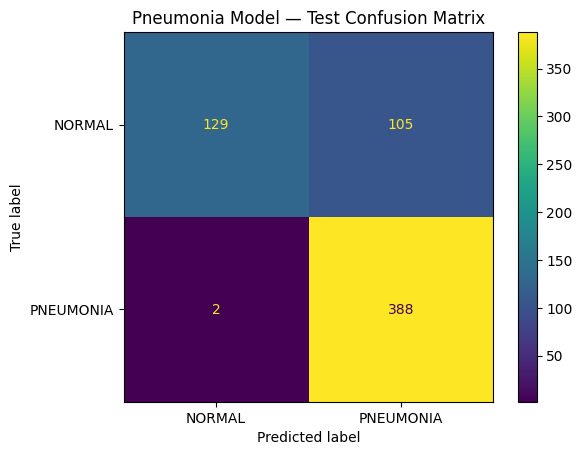

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

display.plot(values_format="d")
plt.title("Pneumonia Model — Test Confusion Matrix")
plt.show()

Saving NORMAL2-IM-0380-0001.jpeg to NORMAL2-IM-0380-0001.jpeg


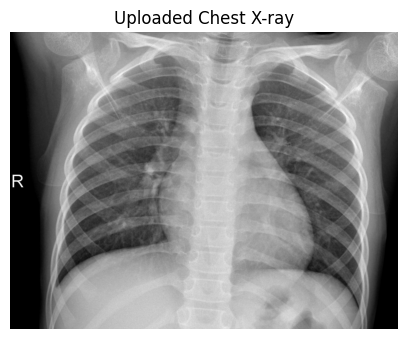

Model output score: 0.4881
Predicted class: NORMAL
Educational prototype only — not a medical diagnosis. Do not use this result to make healthcare decisions.


In [ ]:

from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload an image from your computer
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded))

# Open and prepare the image
image = Image.open(filename).convert("RGB")
image_resized = image.resize((224, 224))

image_array = np.array(image_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Predict
score = float(model.predict(image_array, verbose=0)[0][0])

# Demonstration threshold
predicted_class = "PNEUMONIA" if score >= 0.5 else "NORMAL"

# Display image and result
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Chest X-ray")
plt.show()

print("Model output score:", round(score, 4))
print("Predicted class:", predicted_class)
print(
    "Educational prototype only — not a medical diagnosis. "
    "Do not use this result to make healthcare decisions."
)

In [ ]:

!pip -q install gradio

In [ ]:

import gradio as gr
import numpy as np
from PIL import Image

def predict_pneumonia(image):
    if image is None:
        return "Please upload a chest X-ray image.", {}

    # Prepare image in the same format used by the model
    image = image.convert("RGB").resize((224, 224))
    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    # Predict
    score = float(model.predict(image_array, verbose=0)[0][0])

    predicted_class = (
        "PNEUMONIA" if score >= 0.5 else "NORMAL"
    )

    results = {
        "NORMAL": 1.0 - score,
        "PNEUMONIA": score
    }

    message = (
        f"Model prediction: {predicted_class}\n\n"
        f"Model output score for PNEUMONIA: {score:.4f}\n\n"
        "Educational prototype only. This result is not a "
        "medical diagnosis and must not guide treatment."
    )

    return message, results


with gr.Blocks(title="Pneumonia Screening Research Portal") as demo:

    gr.Markdown(
        """
        # Pneumonia Screening Research Portal

        **Chest X-ray image classification using deep learning**

        Upload an image to see the model's output.

          **Research prototype only:** This tool is not clinically
        validated. Do not use its predictions for diagnosis,
        treatment, or other healthcare decisions.
        """
    )

    with gr.Row():
        image_input = gr.Image(
            type="pil",
            label="Upload Chest X-ray"
        )

        with gr.Column():
            predict_button = gr.Button(
                "Analyze Image",
                variant="primary"
            )
            result_text = gr.Textbox(
                label="Model Output",
                lines=6
            )
            result_scores = gr.Label(
                label="Model Scores",
                num_top_classes=2
            )

    predict_button.click(
        fn=predict_pneumonia,
        inputs=image_input,
        outputs=[result_text, result_scores]
    )

    gr.Markdown(
        """
        **Privacy note:** Do not upload identifiable or real patient
        images to a public demo. The score is a model output, not a
        calibrated probability of disease.
        """
    )

demo.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [ ]:
demo.launch(share=True)

Rerunning server... use `close()` to stop if you need to change `launch()` parameters.
----
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f6ab62f1ef9744bf2e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

import pandas as pd
from IPython.display import display

metrics_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Sensitivity (Recall)",
        "Specificity",
        "Precision",
        "F1-score"
    ],
    "Value": [
        accuracy_score(y_true, y_pred),
        sensitivity,
        specificity,
        precision,
        f1
    ]
})

metrics_table["Value"] = metrics_table["Value"].round(4)
display(metrics_table)

,Metric,Value
0,Accuracy,0.8285
1,Sensitivity (Recall),0.9949
2,Specificity,0.5513
3,Precision,0.7870
4,F1-score,0.8788


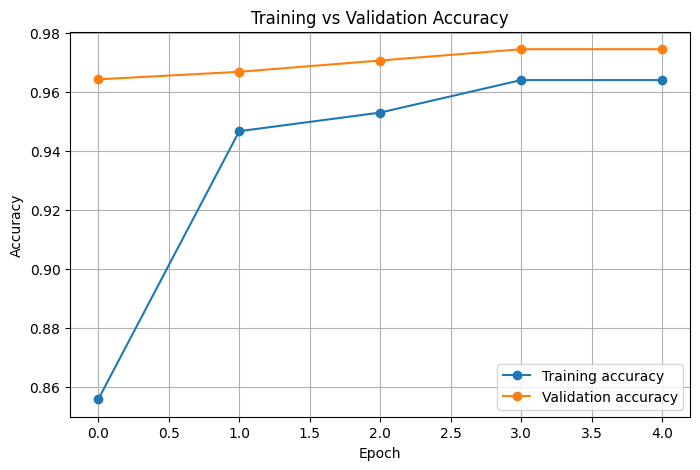

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], marker="o", label="Training accuracy")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

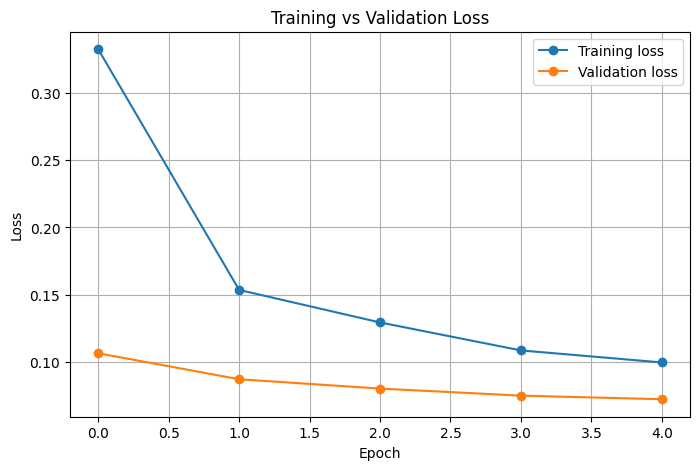

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], marker="o", label="Training loss")
plt.plot(history.history["val_loss"], marker="o", label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:

from pathlib import Path

output_dir = Path("/content/drive/MyDrive/pneumonia_project")
output_dir.mkdir(parents=True, exist_ok=True)

metrics_table.to_csv(
    output_dir / "model_evaluation_metrics.csv",
    index=False
)

print("Metrics saved to:", output_dir / "model_evaluation_metrics.csv")

Metrics saved to: /content/drive/MyDrive/pneumonia_project/model_evaluation_metrics.csv


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
